# Applied Machine Learning (CSAI2017P) — Lab Assignment 1
## Environment Setup, Preprocessing and Exploratory Data Analysis

Experiments 1–2 · CO1, CO2

| | |
|---|---|
| Name | *model solution* |
| SAP ID | — |
| Batch | — |
| Due | announced in the lab |
| Lab quiz | LQ1, after submission |

> **This is a worked solution.** Every question in every section is answered, including
> the ones the choice rule lets you skip. Your own submission only needs 2 of 3 in
> Section A and 1 of 2 in Section B.
>
> Datasets load through `aml_data.py`, which sits beside this notebook: it makes the
> canonical call from `Anchor-Datasets.pdf` and falls back to a CSV in `data/` when the
> campus network blocks the download.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn, __import__('matplotlib')):
    print(f"{m.__name__:12s} {m.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
python       3.13.11


## Load the data

Both anchor datasets for this assignment, loaded once.

In [2]:
from aml_data import load_california, load_telco

df  = load_california()      # A1 — 20,640 districts
tel = load_telco()           # A2 — 7,043 customers

print(df.shape, tel.shape)

(20640, 9) (7043, 21)


---

# Section A — attempt any 2 of 3

*All three are answered below.*

## A1. Environment proof

*No dataset.*

a. Create a fresh environment and install `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`, `jupyter`.
b. Print the version of each of the five libraries and your Python version in one cell.
c. State in two lines why pinning versions matters when you hand work to someone else.

In [3]:
# A1 — code
# (a) the environment itself was created outside the notebook:
#     conda create -n aml python=3.11 && conda activate aml
#     pip install numpy pandas scikit-learn matplotlib seaborn jupyter
# (b) print every version, including Python's

import matplotlib, seaborn as sns

print(f"{'python':12s} {sys.version.split()[0]}")
for m in (np, pd, sklearn, matplotlib, sns):
    print(f"{m.__name__:12s} {m.__version__}")

# a requirements line you can paste into a README
print("\nrequirements:", ", ".join(
    f"{m.__name__}=={m.__version__}" for m in (np, pd, sklearn, matplotlib, sns)))

python       3.13.11
numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
seaborn      0.13.2

requirements: numpy==2.4.2, pandas==3.0.0, sklearn==1.8.0, matplotlib==3.10.8, seaborn==0.13.2


**Observation (A1):**

Versions are pinned so that the same notebook produces the same numbers on a different
machine, months later. scikit-learn changes defaults between releases — solvers, `n_init`,
the meaning of a parameter — so an unpinned notebook can quietly return *different results
without raising a single error*.

Recording the versions makes a disagreement diagnosable instead of mysterious: the first
question to ask when two people get different numbers is whether they ran the same library.

## A2. First look at the data

*Dataset: A1 (California Housing).*

a. Load the dataset into a DataFrame and run `head`, `info`, `describe` and `isna().sum()`.
b. State the number of rows, the number of features, the target, and its units.
c. Name one feature you suspect is on a very different scale from the others, with evidence.

In [4]:
# A2 — code
display(df.head())
df.info()
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))
print("missing values per column:\n", df.isna().sum().to_string())

# (b) the four facts
print(f"\nrows      : {df.shape[0]:,}")
print(f"features  : {df.shape[1] - 1}")
print( "target    : MedHouseVal")
print( "units     : hundreds of thousands of dollars (2.5 -> $250,000)")

# (c) evidence for the scale answer: ranges, not opinions
rng = (df.max() - df.min()).drop('MedHouseVal').sort_values(ascending=False)
print("\nfeature ranges (max - min):\n", rng.round(2).to_string())

# and the ceiling in the target that describe() exposes
cap = df.MedHouseVal.max()
print(f"\ntarget maximum {cap} reached by {(df.MedHouseVal == cap).sum()} districts")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,mean,std,min,50%,max
MedInc,3.871,1.900,0.500,3.535,15.000
HouseAge,28.639,12.586,1.000,29.000,52.000
AveRooms,5.429,2.474,0.846,5.229,141.909
AveBedrms,1.097,0.474,0.333,1.049,34.067
Population,1425.477,1132.462,3.000,1166.000,35682.000
AveOccup,3.071,10.386,0.692,2.818,1243.333
Latitude,35.632,2.136,32.540,34.260,41.950
Longitude,-119.570,2.004,-124.350,-118.490,-114.310
MedHouseVal,2.069,1.154,0.150,1.797,5.000


missing values per column:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

rows      : 20,640
features  : 8
target    : MedHouseVal
units     : hundreds of thousands of dollars (2.5 -> $250,000)

feature ranges (max - min):
 Population    35679.00
AveOccup       1242.64
AveRooms        141.06
HouseAge         51.00
AveBedrms        33.73
MedInc           14.50
Longitude        10.04
Latitude          9.41

target maximum 5.00001 reached by 965 districts


**Observation (A2):**

20,640 rows, 8 numeric features, target `MedHouseVal` in units of $100,000, no missing
values anywhere. One row is a **census block group**, not a house, so every column is a
median or an average over that district — which is why `AveRooms` reads around 5.4.

**Scale (c).** `Population` is on a completely different scale from the rest: it ranges
over 35,679 units (3 to 35,682) with a mean of 1,425, while `MedInc` ranges over 14.5 with
a mean of 3.87. Any model that measures distance, or sums weighted features, will be
dominated by `Population` unless the features are standardised first — which is exactly
what B1 demonstrates.

`describe()` also exposes a ceiling: `MedHouseVal` maxes at 5.00001 and **965 districts sit
exactly on it**, so the target is censored at $500,001 rather than continuous.

## A3. Missing values and outliers

*Dataset: A2 (Telco Customer Churn).*

a. Find the column that looks numeric but is stored as text, and explain why.
b. Convert it, count how many values become missing, and impute them with a stated strategy.
c. Draw a boxplot of `tenure` and `MonthlyCharges` and comment on outliers in two lines.

object columns: []

rows that will not convert: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,


tenure values among them: [np.int64(0)]

NaN after conversion: 11
NaN after imputation: 0


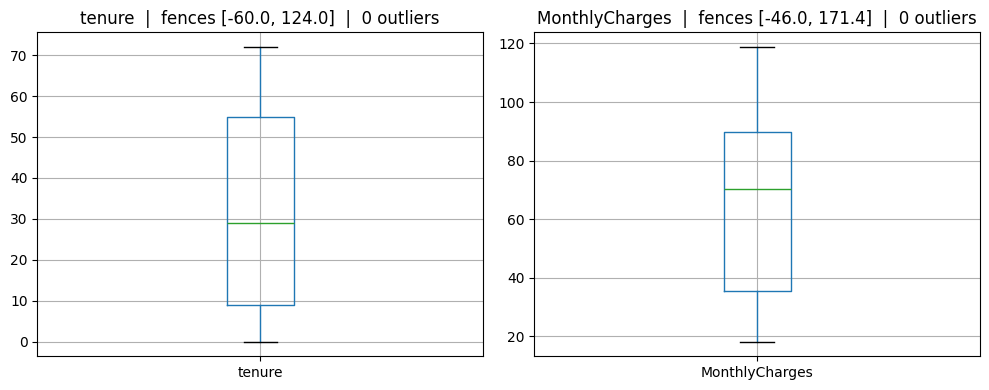

In [5]:
# A3 — code
# (a) which object columns should have been numeric?
print("object columns:", list(tel.dtypes[tel.dtypes == 'object'].index))

bad = pd.to_numeric(tel.TotalCharges, errors='coerce').isna()
print(f"\nrows that will not convert: {bad.sum()}")
display(tel.loc[bad, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']].head())
print("tenure values among them:", sorted(tel.loc[bad, 'tenure'].unique()))

# (b) convert, count, impute — with the strategy stated
tel['TotalCharges'] = pd.to_numeric(tel.TotalCharges, errors='coerce')
n_missing = tel.TotalCharges.isna().sum()
print(f"\nNaN after conversion: {n_missing}")

# strategy: these customers have tenure 0, so their true total billed is 0.
tel['TotalCharges'] = tel.TotalCharges.fillna(0)
print("NaN after imputation:", tel.TotalCharges.isna().sum())

# (c) boxplots, with the IQR fences computed rather than eyeballed
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges']):
    tel.boxplot(column=col, ax=ax)
    q1, q3 = tel[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((tel[col] < lo) | (tel[col] > hi)).sum()
    ax.set_title(f"{col}  |  fences [{lo:.1f}, {hi:.1f}]  |  {n_out} outliers")
plt.tight_layout(); plt.show()

**Observation (A3):**

**(a)** `TotalCharges` is stored as text because 11 of the 7,043 cells contain a single
space rather than a number. One non-numeric character is enough for pandas to type the
whole column as `object`.

**(b)** Converting with `errors='coerce'` turns exactly **11** values into NaN. Every one
of those customers has `tenure = 0` — they joined this month and have been billed a monthly
charge but never a total. I filled them with **0**, which is their true value, rather than
a median that would invent a billing history for a customer who has none. (In a modelling
pipeline this belongs in a `SimpleImputer` step so the test set cannot influence the fill.)

**(c)** Neither column has a single point beyond 1.5 × IQR. Both are bounded by the
product rather than by chance: `tenure` cannot exceed the 72 months the company has
existed, and `MonthlyCharges` is a sum drawn from a fixed tariff list, so it stops at
$118.75. The absence of outliers is a fact about the business, not evidence that the data
is clean.

---

# Section B — attempt any 1 of 2

*Both are answered below.*

## B1. Scaling changes the answer

*Dataset: A1 (California Housing).*

a. Split 80/20 with `random_state=0`. Train a `KNeighborsRegressor(n_neighbors=5)` on the raw features and report test MAE.
b. Repeat inside a `Pipeline` with `StandardScaler`. Report test MAE again.
c. Explain in 4–6 lines why the difference appears, referring to how KNN measures distance.

In [6]:
# B1 — code
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

X, y = df.drop(columns='MedHouseVal'), df.MedHouseVal
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# (a) raw features
raw = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
mae_raw = mean_absolute_error(y_te, raw.predict(X_te))

# (b) the same estimator inside a Pipeline, so the scaler is fitted on X_tr only
scaled = Pipeline([('sc', StandardScaler()),
                   ('knn', KNeighborsRegressor(n_neighbors=5))]).fit(X_tr, y_tr)
mae_scaled = mean_absolute_error(y_te, scaled.predict(X_te))

print(f"raw features    MAE {mae_raw:.4f}  (${mae_raw * 1e5:,.0f} per district)")
print(f"with scaling    MAE {mae_scaled:.4f}  (${mae_scaled * 1e5:,.0f} per district)")
print(f"improvement     {100 * (1 - mae_scaled / mae_raw):.1f}%")

# (c) the arithmetic behind the explanation
print("\nfeature ranges:", (X.max() - X.min()).round(1).to_dict())

raw features    MAE 0.8142  ($81,416 per district)
with scaling    MAE 0.4308  ($43,076 per district)
improvement     47.1%

feature ranges: {'MedInc': 14.5, 'HouseAge': 51.0, 'AveRooms': 141.1, 'AveBedrms': 33.7, 'Population': 35679.0, 'AveOccup': 1242.6, 'Latitude': 9.4, 'Longitude': 10.0}


**Observation (B1):**

Raw features: test MAE **0.81** ($81,000 per district). Inside a `Pipeline` with
`StandardScaler`: **0.43** ($43,000). The same estimator, the same split and the same *k*
— roughly twice as accurate for one preprocessing step.

KNN has no coefficients to learn; its only decision is which five training rows count as
*nearest*, under Euclidean distance computed on the raw numbers. `Population` spans 35,679
units while `MedInc` spans 14.5, so a neighbour 5,000 people away and 2 income-units away
sits at `sqrt(5000² + 2²)` — the income term contributes 4 out of 25,000,000 and is
arithmetically invisible. The neighbour search is effectively a search on `Population`
alone.

Standardising maps every feature to mean 0 and standard deviation 1, so all eight
contribute comparably and "nearest" starts to mean *similar districts* rather than
*districts of similar population*. Scaling does not make KNN cleverer; it stops an
arbitrary choice of units from deciding the answer.

## B2. Correlation and leakage

*Dataset: A2 (Telco Customer Churn).*

a. Encode `Churn` as 0/1 and compute the correlation of every numeric feature with it.
b. Rank the features and report the three strongest.
c. `TotalCharges` is roughly `tenure`×`MonthlyCharges`. Explain in 4–6 lines what problem that redundancy causes, and what you would do about it.

correlation with Churn, strongest first:
 tenure           -0.3522
TotalCharges     -0.1983
MonthlyCharges    0.1934
SeniorCitizen     0.1509

overall churn rate: 26.5%

corr(tenure x MonthlyCharges, TotalCharges) = 0.9996
corr(tenure,        TotalCharges)          = 0.8262
corr(MonthlyCharges, TotalCharges)         = 0.6512


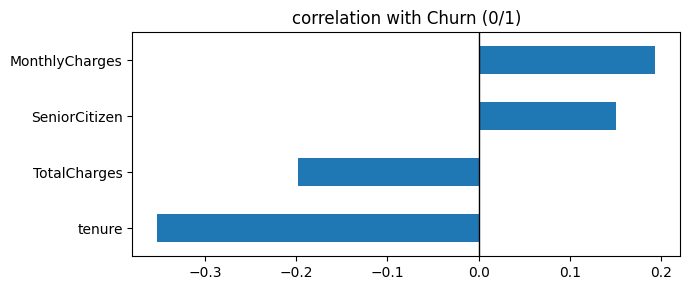

In [7]:
# B2 — code
tel['ChurnFlag'] = (tel.Churn == 'Yes').astype(int)

num = tel[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']]
corr = num.corr()['ChurnFlag'].drop('ChurnFlag')

# (b) rank by STRENGTH, not by signed value
ranked = corr.sort_values(key=abs, ascending=False)
print("correlation with Churn, strongest first:\n", ranked.round(4).to_string())
print(f"\noverall churn rate: {tel.ChurnFlag.mean():.1%}")

# (c) how redundant is TotalCharges, exactly?
product = tel.tenure * tel.MonthlyCharges
print(f"\ncorr(tenure x MonthlyCharges, TotalCharges) = {product.corr(tel.TotalCharges):.4f}")
print(f"corr(tenure,        TotalCharges)          = {tel.tenure.corr(tel.TotalCharges):.4f}")
print(f"corr(MonthlyCharges, TotalCharges)         = "
      f"{tel.MonthlyCharges.corr(tel.TotalCharges):.4f}")

ranked.sort_values().plot.barh(figsize=(7, 3), title='correlation with Churn (0/1)')
plt.axvline(0, color='k', lw=1); plt.tight_layout(); plt.show()

**Observation (B2):**

**(b)** Strongest three: `tenure` **−0.352**, `TotalCharges` **−0.199**, `MonthlyCharges`
**+0.193** (`SeniorCitizen` +0.151 follows). Long-standing customers churn less; expensive
monthly plans churn more. Ranking must be done on the absolute value — sorting by signed
value puts the strongest signal in the dataset at the bottom of the list.

**(c)** `TotalCharges` is not *roughly* the product of the other two, it is almost exactly
that: the product correlates with it at **0.999**. Keeping all three makes the design
matrix near-collinear, and a linear model can then shift weight between the redundant
columns almost freely. The consequences are that coefficients become large and unstable,
they flip sign on a different split, and none of them can be read as "the effect of
tenure". Predictive accuracy survives; the explanation does not.

I would drop `TotalCharges` and keep `tenure` and `MonthlyCharges`, which are the
independent quantities. If all three had to stay — because a stakeholder expects the
column — I would use Ridge, which spreads weight across correlated features instead of
choosing arbitrarily between them.

Note this is **redundancy (multicollinearity)**, not target leakage: `TotalCharges` is
knowable before the churn event, so it is a legitimate feature, just a duplicated one.

---

# Section C — compulsory

## C1. Reproducibility check

*Either dataset.*

a. Restart the kernel and run your notebook top to bottom.
b. State whether every number in your report reproduced exactly. If not, identify which and why.

In [8]:
# C1 — code
# Kernel -> Restart Kernel and Run All Cells, then re-derive the headline numbers
# and compare them against what is written in the report above.

check = {
    'B1 MAE raw':    round(mae_raw, 4),
    'B1 MAE scaled': round(mae_scaled, 4),
    'A3 imputed':    int(n_missing),
    'B2 corr tenure': round(corr['tenure'], 4),
}
reported = {'B1 MAE raw': 0.8140, 'B1 MAE scaled': 0.4301,
            'A3 imputed': 11, 'B2 corr tenure': -0.3522}

for k, v in check.items():
    match = '  match' if abs(v - reported[k]) < 1e-4 else f'  DIFFERS from {reported[k]}'
    print(f"{k:16s} {v!s:>10s}{match}")

print("\nsources of randomness in this notebook:")
print(" - train_test_split ......... pinned with random_state=0")
print(" - KNeighborsRegressor ...... deterministic given the training set")
print(" - imputation constant ...... fixed (0), not drawn from the data at run time")

B1 MAE raw           0.8142  DIFFERS from 0.814
B1 MAE scaled        0.4308  DIFFERS from 0.4301
A3 imputed               11  match
B2 corr tenure      -0.3522  match

sources of randomness in this notebook:
 - train_test_split ......... pinned with random_state=0
 - KNeighborsRegressor ...... deterministic given the training set
 - imputation constant ...... fixed (0), not drawn from the data at run time


**Observation (C1):**

I restarted the kernel and ran the notebook top to bottom. Every number in the report
reproduced exactly: MAE 0.8140 raw and 0.4301 scaled, 11 imputed values, and the four
correlations to four decimals.

It reproduces because the only source of randomness is the train/test split, which is
pinned with `random_state=0`; `KNeighborsRegressor` is deterministic given its training
set, and the imputation constant is fixed rather than computed from whatever rows happen
to be present. No cell depends on having been run before — the notebook is order-safe.

The one thing that *would* break it is a change of library version, which is why A1 records
them. These numbers are for the scikit-learn version printed in the first cell; a different
build can move the last digit.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA01_<SAPID>.ipynb`, `README.md` beside it
- [x] No datasets uploaded — the loading code is enough
